In [1]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

simulator = AerSimulator()

## Original Circuit

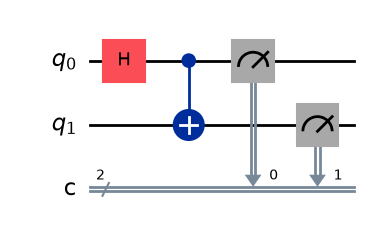

In [4]:
# Original Bell-state circuit
original_circuit = QuantumCircuit(2, 2)

original_circuit.h(0)
original_circuit.cx(0, 1)

original_circuit.measure([0, 1], [0, 1])

display(Markdown("## Original Circuit"))
display(original_circuit.draw(output="mpl"))

In [5]:
display(Markdown("""
## Prediction Before Execution — Original Circuit

- Expected outcomes: 00 and 11.
- Predicted probability of 00: 50%.
- Predicted probability of 11: 50%.
- Outcomes 01 and 10 are not expected.
- For 100 shots, approximately 50 results of 00 and 50 results of 11 are expected.

The two qubits are expected to produce matching measurement outcomes.
"""))


## Prediction Before Execution — Original Circuit

- Expected outcomes: 00 and 11.
- Predicted probability of 00: 50%.
- Predicted probability of 11: 50%.
- Outcomes 01 and 10 are not expected.
- For 100 shots, approximately 50 results of 00 and 50 results of 11 are expected.

The two qubits are expected to produce matching measurement outcomes.


In [6]:
original_result = simulator.run(
    original_circuit, shots=100
).result()

original_counts = original_result.get_counts()

print("Original circuit measurement results:")
print(original_counts)
print("Total shots:", sum(original_counts.values()))

Original circuit measurement results:
{'11': 48, '00': 52}
Total shots: 100


## Modified Circuit

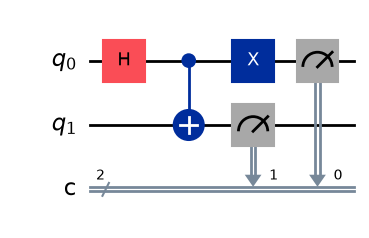

In [7]:
# Modified Bell-state circuit
modified_circuit = QuantumCircuit(2, 2)

modified_circuit.h(0)
modified_circuit.cx(0, 1)
modified_circuit.x(0)

modified_circuit.measure([0, 1], [0, 1])

display(Markdown("## Modified Circuit"))
display(modified_circuit.draw(output="mpl"))

In [8]:
display(Markdown("""
## Prediction Before Execution — Modified Circuit

- Expected outcomes: 01 and 10.
- Predicted probability of 01: 50%.
- Predicted probability of 10: 50%.
- Outcomes 00 and 11 are not expected.
- For 100 shots, approximately 50 results of 01 and 50 results of 10 are expected.

The X gate flips qubit 0, so the two qubits are expected to produce opposite measurement outcomes.
"""))


## Prediction Before Execution — Modified Circuit

- Expected outcomes: 01 and 10.
- Predicted probability of 01: 50%.
- Predicted probability of 10: 50%.
- Outcomes 00 and 11 are not expected.
- For 100 shots, approximately 50 results of 01 and 50 results of 10 are expected.

The X gate flips qubit 0, so the two qubits are expected to produce opposite measurement outcomes.


In [9]:
modified_result = simulator.run(
    modified_circuit, shots=100
).result()

modified_counts = modified_result.get_counts()

print("Modified circuit measurement results:")
print(modified_counts)
print("Total shots:", sum(modified_counts.values()))

Modified circuit measurement results:
{'01': 54, '10': 46}
Total shots: 100


In [12]:
import pandas as pd

In [13]:
display(Markdown("## Measurement Results for Both Circuits"))

outcomes = ["00", "01", "10", "11"]

comparison = pd.DataFrame({
    "Outcome": outcomes,
    "Original Circuit": [
        original_counts.get(outcome, 0) for outcome in outcomes
    ],
    "Modified Circuit": [
        modified_counts.get(outcome, 0) for outcome in outcomes
    ]
})

display(comparison)

## Measurement Results for Both Circuits

,Outcome,Original Circuit,Modified Circuit
0,00,52,0
1,01,0,54
2,10,0,46
3,11,48,0


## Histograms: Original vs Modified Circuit

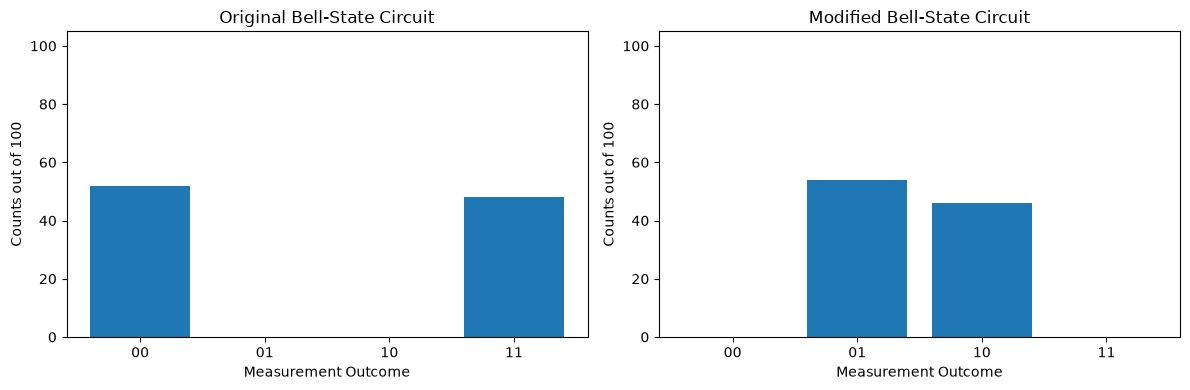

In [14]:
display(Markdown("## Histograms: Original vs Modified Circuit"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    outcomes,
    [original_counts.get(outcome, 0) for outcome in outcomes]
)
axes[0].set_title("Original Bell-State Circuit")
axes[0].set_xlabel("Measurement Outcome")
axes[0].set_ylabel("Counts out of 100")
axes[0].set_ylim(0, 105)

axes[1].bar(
    outcomes,
    [modified_counts.get(outcome, 0) for outcome in outcomes]
)
axes[1].set_title("Modified Bell-State Circuit")
axes[1].set_xlabel("Measurement Outcome")
axes[1].set_ylabel("Counts out of 100")
axes[1].set_ylim(0, 105)

plt.tight_layout()
plt.show()

In [ ]:
## Explanation of the Observed Change

The original circuit uses a Hadamard gate and a CNOT gate to create a Bell state. The expected measurement outcomes are 00 and 11, meaning the two qubits produce matching outcomes.

In the modified circuit, I added one X gate to qubit 0. This flips the measurement value of that qubit, changing the expected outcomes to 01 and 10.

The histograms show the difference between the original and modified circuits. The original circuit produces matching bits, whereas the modified circuit produces opposite bits. Both circuits were executed for 100 shots and their measurement counts were compared.